# Clasificación de tipos tumorales a partir de la expresión génica con aprendizaje automático explicable

## Notebook 02. Preprocesamiento, CV anidada y comparación de modelos (tarea T3)

Trabajo Final de Máster (TFM) realizado en el marco del Máster universitario en Bioinformática y Bioestadística, interuniversitario entre la Universitat Oberta de Catalunya (UOC) y la Universitat de Barcelona (UB). Área 5: Desarrollo de Programas y Aplicaciones.

**Autora:** Ona Sánchez Núñez · **Tutor:** Giuseppe Tardiolo

**Conjunto de datos:** *Gene expression cancer RNA-Seq* (Fiorini, 2016), UCI Machine Learning Repository ([doi:10.24432/C5R88H](https://doi.org/10.24432/C5R88H)), licencia CC BY 4.0. Procede del proyecto The Cancer Genome Atlas (TCGA) Pan-Cancer (Weinstein et al., 2013).

Este notebook continúa el notebook 01 (`qc_eda/01_qc_eda.ipynb`: carga, control de calidad y análisis exploratorio) y contiene los bloques 4 a 8 del flujo de análisis:

0. Entorno y configuración (incluye las versiones de las librerías).
1. Carga de los datos y de la correspondencia de genes.
4. Definición de las particiones de la validación cruzada (cross-validation, CV) anidada.
5. Preprocesamiento.
6. Selección de variables.
7. Ajuste de hiperparámetros y entrenamiento (CV anidada de los cuatro modelos).
8. Evaluación externa: métricas out-of-fold, intervalos de confianza y análisis de errores.

La explicabilidad, la elección del modelo final y la exportación de resultados para la aplicación (bloques 9 a 11) se harán en la siguiente PEC.

Las funciones reutilizables están en el paquete `tfm/` (`modelos.py` y `metricas.py`). Las figuras se guardan en `modelado/figuras/` (300 ppp) y las tablas en `modelado/resultados/`.

## 0. Entorno y configuración

In [1]:
import os
import sys
import warnings
from pathlib import Path

# Evita un aviso de joblib en Windows al contar los núcleos físicos (KMeans)
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))

# Raíz del repositorio (este notebook está en modelado/), para importar el paquete tfm. Si el notebook
# se abre fuera del repositorio (por ejemplo, en Colab), se descarga el repositorio.
RAIZ = Path.cwd().parent
if not (RAIZ / "tfm").exists():
    RAIZ = Path("TFM").resolve()
    if not RAIZ.exists():
        import subprocess
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/OnaSanchez/TFM.git"], check=True)
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import umap
import xgboost
from scipy.stats import mannwhitneyu, fisher_exact
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold

from tfm.datos import CLASES, cargar_datos, validar_datos
from tfm.metricas import bootstrap_estratificado, calcular_metricas, ic_exactitud_exacto
from tfm.modelos import NOMBRES, cv_anidada

# Avisos de convergencia y de genes constantes dentro de alguna partición: no afectan a los resultados
warnings.filterwarnings("ignore")

print("Python:", sys.version.split()[0])
for modulo in (np, pd, scipy, sklearn, xgboost, umap, matplotlib):
    print(f"{modulo.__name__}: {modulo.__version__}")

C:\Users\onasa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.9.13
numpy: 1.23.3
pandas: 2.1.4
scipy: 1.11.4
sklearn: 1.6.1
xgboost: 2.1.4
umap: 0.5.12
matplotlib: 3.8.2


In [2]:
SEED = 1234   # semilla para que los resultados sean reproducibles
DPI = 300     # resolución de las figuras
N_JOBS = -1   # núcleos para la CV (-1 = todos)

DATA_DIR = RAIZ / "Dataset"
FIG_DIR = RAIZ / "modelado" / "figuras"
RES_DIR = RAIZ / "modelado" / "resultados"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

# Mismos colores que en el notebook 01, uno por tipo tumoral
COLORES = {"BRCA": "#a1c9f4", "COAD": "#ffb482", "KIRC": "#8de5a1", "LUAD": "#ff9f9b", "PRAD": "#d0bbff"}
ETIQUETA = {"LR": "Regresión logística", "SVM": "SVM lineal", "RF": "RF", "XGBoost": "XGBoost"}
MODELOS = list(NOMBRES)

## 1. Carga de los datos y de la correspondencia de genes

In [3]:
X, etiquetas = cargar_datos(DATA_DIR)
problemas = validar_datos(X, etiquetas)
print("Problemas de formato:", "; ".join(problemas) if problemas else "ninguno")

# Clases codificadas como enteros 0..4 en el orden de CLASES (XGBoost necesita etiquetas numéricas)
clase_txt = etiquetas["Class"]
y = clase_txt.map({c: i for i, c in enumerate(CLASES)}).values
print(X.shape[0], "muestras x", X.shape[1], "genes")
print(clase_txt.value_counts().reindex(CLASES).to_dict())

# Correspondencia gene_X → símbolo del gen (correspondencia_genes/correspondencia_genes.py)
corr = pd.read_csv(RAIZ / "correspondencia_genes" / "resultados" / "correspondencia_genes.csv",
                   dtype={"entrez_id": str}).set_index("gene_uci")
simbolo = corr["simbolo"].fillna(corr["gene_id_tcga"])  # sin símbolo oficial: se deja el identificador de TCGA
id_por_simbolo = {s: g for g, s in simbolo.items()}

Problemas de formato: ninguno
801 muestras x 20531 genes
{'BRCA': 300, 'COAD': 78, 'KIRC': 146, 'LUAD': 141, 'PRAD': 136}


La correspondencia `gene_X` → gen de TCGA se ha reconstruido con `correspondencia_genes/correspondencia_genes.py`: con el mismo orden de genes y la transformación log2(x + 1), las 78 muestras COAD de UCI coinciden con 78 muestras COAD de TCGA (Broad GDAC Firehose). En este notebook solo se usa en el análisis de errores (bloque 8.3), para mirar la expresión de algunos marcadores conocidos; la confirmación definitiva está pendiente de revisar con el tutor, por lo que esas observaciones se presentan con prudencia.

## 4. Definición de las particiones

- **Particiones externas:** `StratifiedKFold` de 5 particiones (con barajado y semilla fija). Son las mismas para los cuatro modelos, de modo que la comparación se hace sobre exactamente las mismas muestras de prueba.
- **Particiones internas:** `StratifiedKFold` de 3 particiones dentro de cada parte de entrenamiento externa, para elegir los hiperparámetros. Se eligen 3 y no 5 por coste computacional; con unas 640 muestras de entrenamiento, cada partición interna de validación tiene unas 210 muestras (al menos 20 de COAD).

Esquema: entrenamiento externo → CV interna para la selección de genes y el ajuste → mejor flujo reentrenado con todo el entrenamiento externo → prueba externa, que no se usa nunca en la optimización. La CV externa estima el rendimiento de **toda la estrategia de modelado**.

In [4]:
cv_externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_interna = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# Partición externa de cada muestra, para poder reproducirla y revisarla
particion_externa = np.empty(len(y), dtype=int)
for i, (_, prueba) in enumerate(cv_externa.split(X, y)):
    particion_externa[prueba] = i
particiones = pd.DataFrame({"Tipo": clase_txt, "particion_externa": particion_externa})
particiones.to_csv(RES_DIR / "particiones_externas.csv")
pd.crosstab(particiones["particion_externa"], particiones["Tipo"]).reindex(columns=CLASES)

Tipo,BRCA,COAD,KIRC,LUAD,PRAD
particion_externa,,,,,
0,60,16,29,28,28
1,60,15,29,29,27
2,60,15,30,28,27
3,60,16,29,28,27
4,60,16,29,28,27


Cada partición externa de prueba tiene unas 160 muestras con la misma proporción de tipos tumorales que el conjunto completo (entre 15 y 16 muestras de COAD).

## 5. Preprocesamiento

El preprocesamiento forma parte del flujo de cada modelo (`tfm.modelos.crear_pipeline`) y se ajusta solo con la parte de entrenamiento de cada partición:

1. **Genes sin variación** (`VarianceThreshold`): se quitan los genes constantes en el entrenamiento (los 267 genes con varianza 0 del notebook 01 y los que lo sean dentro de una partición).
2. **Escalado** (`StandardScaler`), solo en los modelos lineales (regresión logística y SVM), cuyo ajuste depende de la escala de las variables. Los árboles (bosque aleatorio, Random Forest, RF, y Extreme Gradient Boosting, XGBoost) no lo necesitan.

No se aplica ninguna transformación logarítmica: los datos ya están en escala log2(x + 1) (notebook 01 y `correspondencia_genes/`). No se eliminan muestras atípicas ni se modifican etiquetas.

## 6. Selección de variables

Con 20.531 genes y 801 muestras (p ≫ n), se añade al flujo un filtro univariante: el estadístico F del análisis de la varianza (ANOVA) entre tipos tumorales (`SelectKBest(f_classif)`), que se queda con los *k* genes más discriminantes. El número de genes *k* ∈ {50, 200, 1000} es un hiperparámetro más y se elige en la CV interna. Como la selección se hace dentro de cada partición, no hay fuga de información (data leakage) (Ambroise y McLachlan, 2002). Si varias opciones empatan, se elige la de menos genes (parsimonia).

Además, la regresión logística con penalización Elastic Net hace su propia selección (coeficientes iguales a 0).

## 7. Ajuste de hiperparámetros y entrenamiento

| Modelo | Hiperparámetros fijos | Rejilla (CV interna, F1 macro) |
|---|---|---|
| Regresión logística multinomial penalizada (Elastic Net) | `saga`, pesos de clase equilibrados | *k*; C ∈ {0,05; 0,5}; proporción L1 ∈ {0,2; 0,8} |
| Máquina de vectores de soporte (Support Vector Machine, SVM) lineal | pesos de clase equilibrados | *k*; C ∈ {0,001; 0,01; 0,1} |
| RF | 500 árboles, pesos de clase equilibrados | *k*; atributos por división ∈ {√p, log2 p} |
| XGBoost | 300 árboles, tasa de aprendizaje 0,1, submuestreo 0,8 | *k*; profundidad ∈ {2, 4} |

La métrica de ajuste es el F1 macro: la media no ponderada del F1 de cada clase, que da el mismo peso a las clases frecuentes y a las menos frecuentes.

In [5]:
oof, hiper = {}, []
for nombre in MODELOS:
    oof[nombre], tabla = cv_anidada(nombre, X, y, cv_externa, cv_interna, n_jobs=N_JOBS, semilla=SEED)
    hiper.append(tabla)
    print(f"→ {NOMBRES[nombre]}: {tabla['tiempo_s'].sum():.0f} s en total\n")

# Las particiones externas son las mismas para todos los modelos
assert all((oof[m]["particion"].values == particion_externa).all() for m in MODELOS)

# Predicciones out-of-fold de los cuatro modelos, para revisarlas (y para los bloques 9 a 11, en la siguiente PEC)
pd.concat([oof[m].assign(modelo=m) for m in MODELOS]).to_csv(RES_DIR / "predicciones_oof.csv")

LR · partición 1: {'anova__k': 1000, 'modelo__C': 0.05, 'modelo__l1_ratio': 0.2} · F1 macro interno 0.9987 · 36 s


LR · partición 2: {'anova__k': 200, 'modelo__C': 0.5, 'modelo__l1_ratio': 0.2} · F1 macro interno 1.0000 · 30 s


LR · partición 3: {'anova__k': 200, 'modelo__C': 0.5, 'modelo__l1_ratio': 0.2} · F1 macro interno 1.0000 · 27 s


LR · partición 4: {'anova__k': 1000, 'modelo__C': 0.05, 'modelo__l1_ratio': 0.2} · F1 macro interno 1.0000 · 29 s


LR · partición 5: {'anova__k': 200, 'modelo__C': 0.5, 'modelo__l1_ratio': 0.2} · F1 macro interno 0.9987 · 27 s
→ Regresión logística multinomial penalizada: 149 s en total



...

XGBoost · partición 1: {'anova__k': 1000, 'modelo__max_depth': 2} · F1 macro interno 0.9987 · 23 s


XGBoost · partición 2: {'anova__k': 200, 'modelo__max_depth': 2} · F1 macro interno 0.9973 · 19 s


XGBoost · partición 3: {'anova__k': 200, 'modelo__max_depth': 2} · F1 macro interno 0.9948 · 20 s


XGBoost · partición 4: {'anova__k': 50, 'modelo__max_depth': 2} · F1 macro interno 0.9948 · 20 s


XGBoost · partición 5: {'anova__k': 50, 'modelo__max_depth': 2} · F1 macro interno 0.9974 · 22 s
→ XGBoost: 105 s en total



In [6]:
# Hiperparámetros elegidos en cada partición externa
hiper = pd.concat(hiper, ignore_index=True)
hiper.to_csv(RES_DIR / "hiperparametros_por_particion.csv", index=False)
hiper.round(4)

,modelo,particion,anova__k,modelo__C,modelo__l1_ratio,f1_macro_interno,tiempo_s,modelo__max_features,modelo__max_depth
0,LR,0,1000,0.050,0.2,0.9987,36.3284,NaN,NaN
1,LR,1,200,0.500,0.2,1.0000,30.4480,NaN,NaN
2,LR,2,200,0.500,0.2,1.0000,27.1162,NaN,NaN
3,LR,3,1000,0.050,0.2,1.0000,28.5630,NaN,NaN
4,LR,4,200,0.500,0.2,0.9987,26.5047,NaN,NaN
5,SVM,0,200,0.001,NaN,1.0000,6.2616,NaN,NaN
6,SVM,1,200,0.001,NaN,1.0000,6.6554,NaN,NaN
7,SVM,2,200,0.001,NaN,1.0000,6.3930,NaN,NaN
8,SVM,3,200,0.010,NaN,1.0000,6.6980,NaN,NaN
9,SVM,4,200,0.001,NaN,1.0000,6.4869,NaN,NaN


**Resultado:** el F1 macro interno es igual o superior a 0,995 en todas las particiones y modelos: el problema es casi separable y muchas combinaciones empatan. La SVM lineal elige siempre 200 genes (y C = 0,001 en cuatro de cinco particiones); la regresión logística alterna entre 200 y 1.000 genes, siempre con proporción L1 = 0,2; el RF prefiere 1.000 genes (cuatro de cinco particiones) y XGBoost, profundidad 2 con 50, 200 o 1.000 genes. La SVM es el modelo más rápido (unos 7 s por partición externa, incluida la CV interna).

## 8. Evaluación externa

### 8.1 Métricas globales con predicciones out-of-fold

Cada muestra se predice una sola vez, con el modelo de la partición externa en la que estaba en la parte de prueba. Con estas 801 predicciones out-of-fold se calculan las métricas globales y la matriz de confusión conjunta. Los intervalos de confianza del 95 % se obtienen por bootstrap estratificado (2.000 réplicas, remuestreando dentro de cada clase real): reflejan la incertidumbre debida a las muestras evaluadas, no la de reentrenar los modelos con otros datos.

In [7]:
filas = []
for nombre in MODELOS:
    ic = bootstrap_estratificado(oof[nombre]["real"], oof[nombre]["pred"], n=2000, semilla=SEED)
    for metrica, fila in ic.iterrows():
        filas.append({"modelo": nombre, "metrica": metrica, **fila.to_dict()})
metricas_ic = pd.DataFrame(filas)
metricas_ic.to_csv(RES_DIR / "metricas_globales_ic95.csv", index=False)

# Tabla «estimación [IC 95 %]» con un modelo por fila
metricas_ic["valor"] = [f"{f.estimacion:.4f} [{f.ic_inferior:.4f}–{f.ic_superior:.4f}]" for f in metricas_ic.itertuples()]
tabla_metricas = metricas_ic.pivot(index="modelo", columns="metrica", values="valor")
tabla_metricas = tabla_metricas.reindex(index=MODELOS, columns=list(calcular_metricas([0], [0])))
tabla_metricas.rename(index=ETIQUETA)

metrica,F1 macro,Exactitud equilibrada,Exactitud,Precisión macro,Sensibilidad macro
modelo,,,,,
Regresión logística,0.9990 [0.9969–1.0000],0.9986 [0.9957–1.0000],0.9988 [0.9963–1.0000],0.9993 [0.9980–1.0000],0.9986 [0.9957–1.0000]
SVM lineal,1.0000 [1.0000–1.0000],1.0000 [1.0000–1.0000],1.0000 [1.0000–1.0000],1.0000 [1.0000–1.0000],1.0000 [1.0000–1.0000]
RF,0.9958 [0.9916–0.9990],0.9944 [0.9887–0.9986],0.9950 [0.9900–0.9988],0.9974 [0.9948–0.9993],0.9944 [0.9887–0.9986]
XGBoost,0.9959 [0.9898–1.0000],0.9945 [0.9869–1.0000],0.9963 [0.9913–1.0000],0.9973 [0.9932–1.0000],0.9945 [0.9869–1.0000]


In [8]:
# Si un modelo no comete errores, todas las réplicas bootstrap dan 1 y el intervalo [1–1] no refleja la
# incertidumbre. Como complemento, intervalo exacto de Clopper-Pearson de la exactitud (n = 801)
filas = []
for nombre in MODELOS:
    aciertos = int((oof[nombre]["real"] == oof[nombre]["pred"]).sum())
    inf, sup = ic_exactitud_exacto(aciertos, len(y))
    filas.append({"modelo": ETIQUETA[nombre], "errores": len(y) - aciertos, "exactitud": aciertos / len(y),
                  "IC 95 % exacto": f"[{inf:.4f}–{sup:.4f}]"})
ic_exacto = pd.DataFrame(filas).set_index("modelo")
ic_exacto.to_csv(RES_DIR / "exactitud_ic_exacto.csv")
ic_exacto.round(4)

,errores,exactitud,IC 95 % exacto
modelo,,,
Regresión logística,1,0.9988,[0.9931–1.0000]
SVM lineal,0,1.0000,[0.9954–1.0000]
RF,4,0.9950,[0.9873–0.9986]
XGBoost,3,0.9963,[0.9891–0.9992]


In [9]:
# Métricas en cada partición externa (media y desviación estándar entre particiones)
filas = []
for nombre in MODELOS:
    for i, g in oof[nombre].groupby("particion"):
        filas.append({"modelo": nombre, "particion": i, **calcular_metricas(g["real"], g["pred"])})
por_particion = pd.DataFrame(filas)
por_particion.to_csv(RES_DIR / "metricas_por_particion.csv", index=False)
por_particion.groupby("modelo")[["F1 macro", "Exactitud equilibrada", "Exactitud"]].agg(["mean", "std"]).reindex(MODELOS).round(4)

F1 macro         Exactitud equilibrada         Exactitud        
            mean     std                  mean     std      mean     std
modelo                                                                  
LR        0.9989  0.0024                0.9986  0.0032    0.9988  0.0028
SVM       1.0000  0.0000                1.0000  0.0000    1.0000  0.0000
RF        0.9958  0.0044                0.9943  0.0059    0.9950  0.0052
XGBoost   0.9959  0.0056                0.9946  0.0074    0.9963  0.0056

In [10]:
# Precisión, sensibilidad y F1 de cada clase
filas = []
for nombre in MODELOS:
    informe = classification_report(oof[nombre]["real"], oof[nombre]["pred"], target_names=CLASES,
                                    output_dict=True, zero_division=0)
    for c in CLASES:
        filas.append({"modelo": nombre, "clase": c, "precision": informe[c]["precision"],
                      "sensibilidad": informe[c]["recall"], "f1": informe[c]["f1-score"],
                      "muestras": informe[c]["support"]})
por_clase = pd.DataFrame(filas)
por_clase.to_csv(RES_DIR / "metricas_por_clase.csv", index=False)
por_clase.pivot(index="clase", columns="modelo", values="f1")[MODELOS].round(4)

modelo,LR,SVM,RF,XGBoost
clase,,,,
BRCA,0.9983,1.0,0.9934,0.9967
COAD,1.0000,1.0,1.0000,0.9935
KIRC,1.0000,1.0,0.9966,1.0000
LUAD,0.9964,1.0,0.9892,0.9929
PRAD,1.0000,1.0,1.0000,0.9963


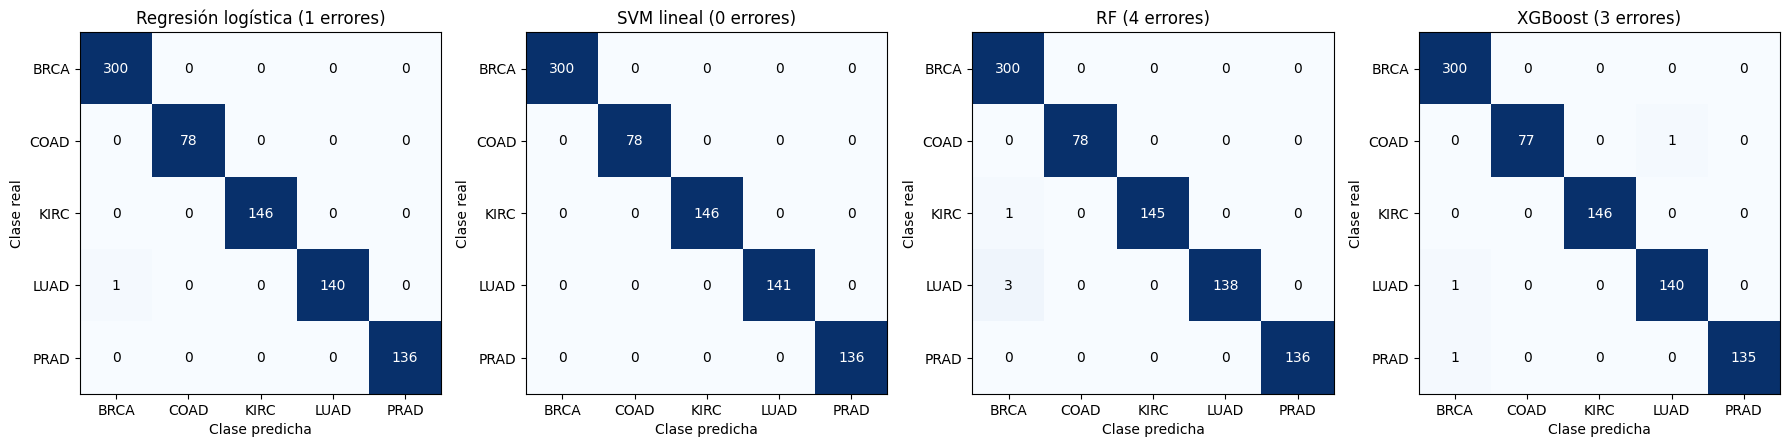

In [11]:
# Matriz de confusión conjunta (out-of-fold) de cada modelo
fig, axs = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, nombre in zip(axs, MODELOS):
    real, pred = oof[nombre]["real"], oof[nombre]["pred"]
    cm = confusion_matrix(real, pred, labels=range(5))
    ax.imshow(cm, cmap="Blues", vmax=cm.max() * 0.25)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10, color="white" if i == j else "black")
    ax.set_xticks(range(5), CLASES)
    ax.set_yticks(range(5), CLASES)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{ETIQUETA[nombre]} ({(real != pred).sum()} errores)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_matrices_confusion.png", dpi=DPI)
plt.show()

**Resultado:**
- Los cuatro modelos tienen un rendimiento muy alto. La **SVM lineal** clasifica correctamente las 801 muestras (F1 macro 1,000); la **regresión logística** comete 1 error (F1 macro 0,999 [0,997–1,000]), **XGBoost** 3 (0,996 [0,990–1,000]) y el **RF** 4 (0,996 [0,992–0,999]).
- Los intervalos se solapan: con tan pocos errores, las diferencias entre modelos no son concluyentes. Cuando no hay errores, el bootstrap da un intervalo degenerado [1–1]; el intervalo exacto de Clopper-Pearson de la exactitud de la SVM, [0,995–1,000], indica que la exactitud real podría ser algo inferior a 1.
- La variabilidad entre particiones externas es pequeña (desviación estándar del F1 macro ≤ 0,006).
- Por clase, los pocos errores afectan sobre todo a LUAD (F1 entre 0,989 y 1) y BRCA. COAD, la clase con menos muestras, tiene F1 = 1 en tres de los cuatro modelos, aunque con solo 78 muestras su estimación es la más incierta.
- Se confirma la hipótesis H1: varios modelos clásicos rinden casi igual, así que la elección del modelo final (siguiente PEC) tendrá que apoyarse también en el número de genes, la estabilidad y el coste.

### 8.2 Coste computacional y número de genes

In [12]:
coste = hiper.groupby("modelo").agg(tiempo_medio_s=("tiempo_s", "mean"),
                                     k_mediana=("anova__k", "median"),
                                     k_elegidos=("anova__k", lambda s: ", ".join(map(str, s))))
coste.to_csv(RES_DIR / "coste_y_genes.csv")
coste.reindex(MODELOS).round(1)

,tiempo_medio_s,k_mediana,k_elegidos
modelo,,,
LR,29.8,200.0,"1000, 200, 200, 1000, 200"
SVM,6.5,200.0,"200, 200, 200, 200, 200"
RF,13.1,1000.0,"1000, 50, 1000, 1000, 1000"
XGBoost,20.9,200.0,"1000, 200, 200, 50, 50"


**Resultado:** la SVM lineal, la regresión logística y XGBoost usan una mediana de 200 genes y el RF, 1.000. La SVM es la más rápida (unos 7 s por partición externa, incluida la CV interna) y el RF, el más lento.

### 8.3 Análisis de errores

Se comprueba si las muestras que el notebook 01 marcó como atípicas (`qc_eda/resultados/qc_muestras.csv`) y las del grupo pequeño de BRCA en el UMAP, junto con las dos muestras de LUAD que aparecían a su lado, son las que los modelos clasifican peor. Para localizar esas muestras se repite el UMAP del notebook 01 (mismos parámetros y semilla) y se separan los dos grupos de BRCA con *k*-medias (*k* = 2) sobre sus coordenadas. Es un análisis de errores: no se modifica ninguna etiqueta ni se elimina ninguna muestra.

  File "C:\Users\onasa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.9_3.9.3568.0_x64__qbz5n2kfra8p0\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.9_3.9.3568.0_x64__qbz5n2kfra8p0\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.9_3.9.3568.0_x64__qbz5n2kfra8p0\lib\subprocess.py", line 1420, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


BRCA en el grupo pequeño: 48 · LUAD a su lado: ['sample_129', 'sample_599']


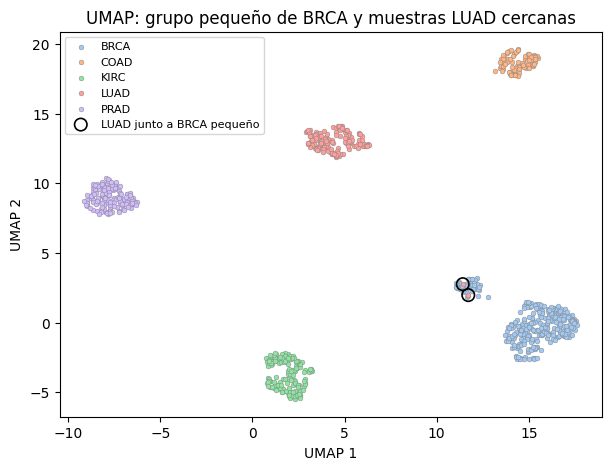

In [13]:
# Mismo UMAP que el notebook 01: 50 componentes de la PCA de los datos centrados
X_ok = X.loc[:, X.var() > 0]
X_pca = PCA(n_components=50, random_state=SEED).fit_transform(X_ok.values)
X_umap = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=SEED).fit_transform(X_pca)
coords = pd.DataFrame({"UMAP1": X_umap[:, 0], "UMAP2": X_umap[:, 1], "Tipo": clase_txt}, index=X.index)

# Dos grupos de BRCA en el UMAP: el pequeño es el de menos muestras
brca = coords[coords["Tipo"] == "BRCA"]
grupo = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(brca[["UMAP1", "UMAP2"]])
pequeno = np.argmin(np.bincount(grupo))
brca_pequeno = brca.index[grupo == pequeno]
centro = brca.loc[brca_pequeno, ["UMAP1", "UMAP2"]].mean()

# Muestras LUAD junto al grupo pequeño: más cerca de su centro que la muestra BRCA más alejada del grupo
radio = np.linalg.norm(brca.loc[brca_pequeno, ["UMAP1", "UMAP2"]] - centro, axis=1).max()
luad = coords[coords["Tipo"] == "LUAD"]
dist_luad = np.linalg.norm(luad[["UMAP1", "UMAP2"]] - centro, axis=1)
luad_junto = luad.index[dist_luad <= radio * 1.2]
coords["grupo_umap"] = "resto"
coords.loc[brca_pequeno, "grupo_umap"] = "BRCA grupo pequeño"
coords.loc[luad_junto, "grupo_umap"] = "LUAD junto a BRCA pequeño"
print("BRCA en el grupo pequeño:", len(brca_pequeno), "· LUAD a su lado:", list(luad_junto))

fig, ax = plt.subplots(figsize=(7, 5))
for c in CLASES:
    m = coords["Tipo"] == c
    ax.scatter(coords.loc[m, "UMAP1"], coords.loc[m, "UMAP2"], s=12, color=COLORES[c], edgecolor="gray",
               linewidth=0.3, label=c)
ax.scatter(coords.loc[luad_junto, "UMAP1"], coords.loc[luad_junto, "UMAP2"], s=80, facecolor="none",
           edgecolor="black", linewidth=1.2, label="LUAD junto a BRCA pequeño")
ax.set_title("UMAP: grupo pequeño de BRCA y muestras LUAD cercanas")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.legend(fontsize=8)
plt.savefig(FIG_DIR / "fig7_umap_grupos.png", dpi=DPI)
plt.show()

In [14]:
qc = pd.read_csv(RAIZ / "qc_eda" / "resultados" / "qc_muestras.csv", index_col=0)

errores = pd.DataFrame({"Tipo": clase_txt, "Atípica QC": qc["Atípica"], "Grupo UMAP": coords["grupo_umap"]})
for nombre in MODELOS:
    errores[f"pred_{nombre}"] = [CLASES[p] for p in oof[nombre]["pred"]]
    # Probabilidad asignada a la clase real (no disponible en la SVM, que no da probabilidades)
    if nombre != "SVM":
        punt = oof[nombre][[f"punt_{c}" for c in range(5)]].values
        errores[f"prob_real_{nombre}"] = punt[np.arange(len(y)), y]
errores["modelos_que_fallan"] = sum((errores[f"pred_{m}"] != errores["Tipo"]).astype(int) for m in MODELOS)
errores.to_csv(RES_DIR / "analisis_errores.csv")

mal = errores[errores["modelos_que_fallan"] > 0].sort_values("modelos_que_fallan", ascending=False)
print("Muestras mal clasificadas por al menos un modelo:", len(mal))
mal[["Tipo", "Atípica QC", "Grupo UMAP", "modelos_que_fallan"] + [f"pred_{m}" for m in MODELOS]]

Muestras mal clasificadas por al menos un modelo: 6


,Tipo,Atípica QC,Grupo UMAP,modelos_que_fallan,pred_LR,pred_SVM,pred_RF,pred_XGBoost
sample_129,LUAD,False,LUAD junto a BRCA pequeño,2,BRCA,LUAD,BRCA,LUAD
sample_599,LUAD,True,LUAD junto a BRCA pequeño,2,LUAD,LUAD,BRCA,BRCA
sample_61,KIRC,False,resto,1,KIRC,KIRC,BRCA,KIRC
sample_338,PRAD,False,resto,1,PRAD,PRAD,PRAD,BRCA
sample_507,LUAD,False,resto,1,LUAD,LUAD,BRCA,LUAD
sample_510,COAD,False,resto,1,COAD,COAD,COAD,LUAD


In [15]:
# ¿Las muestras atípicas o de los grupos del UMAP se clasifican peor? (prueba exacta de Fisher)
fallo = errores["modelos_que_fallan"] > 0
grupos = {"Atípicas en el QC": errores["Atípica QC"],
          "BRCA grupo pequeño": errores["Grupo UMAP"] == "BRCA grupo pequeño",
          "LUAD junto a BRCA pequeño": errores["Grupo UMAP"] == "LUAD junto a BRCA pequeño"}
for nombre_grupo, marca in grupos.items():
    tabla = pd.crosstab(marca, fallo).reindex(index=[False, True], columns=[False, True], fill_value=0)
    _, p = fisher_exact(tabla.values)
    print(f"{nombre_grupo}: {marca.sum()} muestras · con algún error {fallo[marca].mean() * 100:.1f} % frente a "
          f"{fallo[~marca].mean() * 100:.1f} % del resto (p = {p:.3g})")

# Confianza: probabilidad de la clase real en atípicas y no atípicas (modelos con probabilidades)
for nombre in ["LR", "RF", "XGBoost"]:
    a = errores.loc[errores["Atípica QC"], f"prob_real_{nombre}"]
    b = errores.loc[~errores["Atípica QC"], f"prob_real_{nombre}"]
    p = mannwhitneyu(a, b, alternative="less").pvalue
    print(f"{ETIQUETA[nombre]}: probabilidad mediana de la clase real {a.median():.3f} (atípicas) frente a "
          f"{b.median():.3f} (resto); Mann-Whitney unilateral p = {p:.3g}")

Atípicas en el QC: 20 muestras · con algún error 5.0 % frente a 0.6 % del resto (p = 0.141)
BRCA grupo pequeño: 48 muestras · con algún error 0.0 % frente a 0.8 % del resto (p = 1)
LUAD junto a BRCA pequeño: 2 muestras · con algún error 100.0 % frente a 0.5 % del resto (p = 4.68e-05)
Regresión logística: probabilidad mediana de la clase real 0.991 (atípicas) frente a 0.994 (resto); Mann-Whitney unilateral p = 0.0978
RF: probabilidad mediana de la clase real 0.934 (atípicas) frente a 0.980 (resto); Mann-Whitney unilateral p = 0.000749
XGBoost: probabilidad mediana de la clase real 0.996 (atípicas) frente a 0.997 (resto); Mann-Whitney unilateral p = 0.168


In [16]:
# Exploración con marcadores conocidos: grupo pequeño de BRCA y muestras LUAD mal clasificadas
MARCADORES_EXPLORACION = ["ESR1", "PGR", "GATA3", "FOXA1", "ERBB2", "KRT5", "KRT14", "FOXC1", "SFRP1",
                          "NKX2-1", "SFTPC", "NAPSA", "TP63", "SOX2", "KRT6A"]
grupo_exp = coords["Tipo"] + " · " + coords["grupo_umap"]
grupo_exp[coords["Tipo"] == "LUAD"] = "LUAD · resto"
for m in luad_junto:
    grupo_exp[m] = f"LUAD · {m}"
expr_grupos = X[[id_por_simbolo[s] for s in MARCADORES_EXPLORACION]].groupby(grupo_exp).median().T
expr_grupos.index = MARCADORES_EXPLORACION
columnas = ["BRCA · BRCA grupo pequeño", "BRCA · resto"] + [f"LUAD · {m}" for m in luad_junto] + ["LUAD · resto"]
expr_grupos = expr_grupos[columnas]
expr_grupos.to_csv(RES_DIR / "marcadores_grupos_umap.csv")
expr_grupos.round(1)

,BRCA · BRCA grupo pequeño,BRCA · resto,LUAD · sample_129,LUAD · sample_599,LUAD · resto
ESR1,6.5,13.2,1.9,4.8,6.9
PGR,4.2,10.2,1.8,6.3,5.3
GATA3,9.4,13.6,8.6,5.4,6.2
FOXA1,6.2,12.8,9.0,4.4,10.6
ERBB2,11.8,12.9,13.0,10.7,12.6
KRT5,12.4,9.4,8.3,6.4,5.3
KRT14,9.7,9.1,5.0,10.9,2.4
FOXC1,11.1,6.8,11.7,7.1,7.4
SFRP1,12.8,8.7,12.0,8.8,5.3
NKX2-1,0.0,0.0,1.0,10.3,11.6


**Resultado:**
- Solo **6 de las 801 muestras** se clasifican mal con algún modelo, y ninguna con más de dos. Las dos muestras LUAD que en el UMAP aparecen junto al grupo pequeño de BRCA (`sample_129` y `sample_599`) son las únicas que fallan dos modelos, y siempre se confunden con BRCA: estar en esa posición del UMAP se asocia claramente con los errores (prueba exacta de Fisher, p = 4,7·10⁻⁵, aunque con solo dos muestras).
- De las 20 muestras atípicas del QC solo una (`sample_599`) se clasifica mal (5 % frente a 0,6 % del resto; p = 0,14). Aun así, el RF les asigna menos probabilidad a su clase real (mediana 0,934 frente a 0,980; p < 0,001); en la regresión logística y XGBoost la diferencia no es significativa.
- Las 48 muestras del grupo pequeño de BRCA se clasifican todas bien.
- **Exploración con marcadores** (tabla anterior): el grupo pequeño de BRCA tiene ESR1, PGR, GATA3 y FOXA1 bajos y KRT5, KRT14, FOXC1 y SFRP1 altos, un perfil compatible con el subtipo basal (similar al triple negativo). `sample_129` tiene NKX2-1, SFTPC y NAPSA bajos y TP63, SOX2 y KRT6A altos, un perfil más propio de un carcinoma escamoso que de un adenocarcinoma, que comparte con el BRCA basal el programa de queratinas basales; `sample_599` conserva NKX2-1, pero con poca expresión de surfactantes y NAPSA y KRT14 alto. Son observaciones exploratorias: sin metadatos (subtipo PAM50 o revisión histológica) no pueden confirmarse, y no se ha modificado ninguna etiqueta.